# 2024 Formula 1 Motorsport Race Analysis

## Project Overview

This notebook analyzes Formula 1 race and lap-time data from the 2024 season.

The analysis focuses on:

- Driver finishing performance
- Lap-time consistency
- Championship points
- Race-by-race relative pace
- Tyre-age performance
- Exploratory tyre degradation trends

The data was collected using FastF1 and processed using Python, Pandas, NumPy, and Matplotlib.

## Research Question

How do driver pace, consistency, tyre strategy, and finishing performance vary across the 2024 Formula 1 season?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
ROOT = Path.cwd().parent

RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "outputs" / "figures"

print("Project root:", ROOT)
print("Raw data:", RAW_DIR)
print("Processed data:", PROCESSED_DIR)
print("Figures:", FIG_DIR)

Project root: C:\Users\User\Latihan\.vscode\Project_1_F1_Motorsport_Race_Analysis
Raw data: C:\Users\User\Latihan\.vscode\Project_1_F1_Motorsport_Race_Analysis\data\raw
Processed data: C:\Users\User\Latihan\.vscode\Project_1_F1_Motorsport_Race_Analysis\data\processed
Figures: C:\Users\User\Latihan\.vscode\Project_1_F1_Motorsport_Race_Analysis\outputs\figures


In [3]:
results = pd.read_csv(RAW_DIR / "race_results_2024.csv")
laps = pd.read_csv(RAW_DIR / "race_laps_2024.csv")

print("Race-result rows:", len(results))
print("Lap rows:", len(laps))

Race-result rows: 479
Lap rows: 26604


In [4]:
print("Race Results:")
display(results.head())

Race Results:


,Year,RoundNumber,EventName,Abbreviation,FullName,TeamName,Position,GridPosition,Points,Status,Laps
0,2024,1,Bahrain Grand Prix,VER,Max Verstappen,Red Bull Racing,1.0,1.0,26.0,Finished,57.0
1,2024,1,Bahrain Grand Prix,PER,Sergio Perez,Red Bull Racing,2.0,5.0,18.0,Finished,57.0
2,2024,1,Bahrain Grand Prix,SAI,Carlos Sainz,Ferrari,3.0,4.0,15.0,Finished,57.0
3,2024,1,Bahrain Grand Prix,LEC,Charles Leclerc,Ferrari,4.0,2.0,12.0,Finished,57.0
4,2024,1,Bahrain Grand Prix,RUS,George Russell,Mercedes,5.0,3.0,10.0,Finished,57.0


In [5]:
print("Lap Data:")
display(laps.head())

Lap Data:


,Year,RoundNumber,EventName,Driver,DriverNumber,Team,LapNumber,LapTime,Stint,Compound,TyreLife,FreshTyre,TrackStatus,PitOutTime,PitInTime,IsPersonalBest
0,2024,1,Bahrain Grand Prix,VER,1,Red Bull Racing,1.0,0 days 00:01:37.284000,1.0,SOFT,4.0,False,12,NaN,NaN,False
1,2024,1,Bahrain Grand Prix,VER,1,Red Bull Racing,2.0,0 days 00:01:36.296000,1.0,SOFT,5.0,False,1,NaN,NaN,True
2,2024,1,Bahrain Grand Prix,VER,1,Red Bull Racing,3.0,0 days 00:01:36.753000,1.0,SOFT,6.0,False,1,NaN,NaN,False
3,2024,1,Bahrain Grand Prix,VER,1,Red Bull Racing,4.0,0 days 00:01:36.647000,1.0,SOFT,7.0,False,1,NaN,NaN,False
4,2024,1,Bahrain Grand Prix,VER,1,Red Bull Racing,5.0,0 days 00:01:37.173000,1.0,SOFT,8.0,False,1,NaN,NaN,False


In [6]:
print("Race Results columns:")
print(results.columns.tolist())

print("\nLap Data columns:")
print(laps.columns.tolist())

Race Results columns:
['Year', 'RoundNumber', 'EventName', 'Abbreviation', 'FullName', 'TeamName', 'Position', 'GridPosition', 'Points', 'Status', 'Laps']

Lap Data columns:
['Year', 'RoundNumber', 'EventName', 'Driver', 'DriverNumber', 'Team', 'LapNumber', 'LapTime', 'Stint', 'Compound', 'TyreLife', 'FreshTyre', 'TrackStatus', 'PitOutTime', 'PitInTime', 'IsPersonalBest']


In [7]:
print("=== Race Results ===")
results.info()

print("\n=== Lap Data ===")
laps.info()

=== Race Results ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 479 entries, 0 to 478
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Year          479 non-null    int64  
 1   RoundNumber   479 non-null    int64  
 2   EventName     479 non-null    object 
 3   Abbreviation  479 non-null    object 
 4   FullName      479 non-null    object 
 5   TeamName      479 non-null    object 
 6   Position      479 non-null    float64
 7   GridPosition  479 non-null    float64
 8   Points        479 non-null    float64
 9   Status        479 non-null    object 
 10  Laps          479 non-null    float64
dtypes: float64(4), int64(2), object(5)
memory usage: 41.3+ KB

=== Lap Data ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26604 entries, 0 to 26603
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Year            26604 non-null

In [8]:
print("Race Results shape:", results.shape)
print("Lap Data shape:", laps.shape)

Race Results shape: (479, 11)
Lap Data shape: (26604, 16)


In [9]:
# Convert LapTime to timedelta
laps["LapTime"] = pd.to_timedelta(laps["LapTime"], errors="coerce")

# Convert to seconds
laps["LapTimeSeconds"] = laps["LapTime"].dt.total_seconds()

print("LapTime converted successfully.")
display(laps[["Driver", "LapNumber", "LapTime", "LapTimeSeconds"]].head())

LapTime converted successfully.


,Driver,LapNumber,LapTime,LapTimeSeconds
0,VER,1.0,0 days 00:01:37.284000,97.284
1,VER,2.0,0 days 00:01:36.296000,96.296
2,VER,3.0,0 days 00:01:36.753000,96.753
3,VER,4.0,0 days 00:01:36.647000,96.647
4,VER,5.0,0 days 00:01:37.173000,97.173


In [10]:
print("Total lap rows:", len(laps))
print("Valid LapTimeSeconds:", laps["LapTimeSeconds"].notna().sum())
print("Missing LapTimeSeconds:", laps["LapTimeSeconds"].isna().sum())

display(laps["LapTimeSeconds"].describe())

Total lap rows: 26604
Valid LapTimeSeconds: 26381
Missing LapTimeSeconds: 223


count    26381.000000
mean        92.727333
std         60.498621
min         67.694000
25%         81.964000
50%         89.076000
75%         98.704000
max       2526.253000
Name: LapTimeSeconds, dtype: float64

In [11]:
print("Missing values in important lap columns:")

important_columns = [
    "EventName",
    "Driver",
    "LapNumber",
    "LapTimeSeconds",
    "Compound",
    "TyreLife"
]

missing = laps[important_columns].isna().sum()

display(missing)

Missing values in important lap columns:


EventName           0
Driver              0
LapNumber           0
LapTimeSeconds    223
Compound            0
TyreLife            0
dtype: int64

In [12]:
clean_laps = laps.copy()

# Keep rows with the basic information required for lap analysis
clean_laps = clean_laps.dropna(
    subset=["EventName", "Driver", "LapNumber", "LapTimeSeconds"]
)

print("Rows after removing missing essential data:", len(clean_laps))

Rows after removing missing essential data: 26381


In [13]:
print("10 lap times tercepat:")
display(
    clean_laps[
        ["EventName", "Driver", "LapNumber", "LapTimeSeconds"]
    ]
    .sort_values("LapTimeSeconds")
    .head(10)
)

print("\n10 lap times terlambat:")
display(
    clean_laps[
        ["EventName", "Driver", "LapNumber", "LapTimeSeconds"]
    ]
    .sort_values("LapTimeSeconds", ascending=False)
    .head(10)
)

10 lap times tercepat:


,EventName,Driver,LapNumber,LapTimeSeconds
12406,Austrian Grand Prix,ALO,70.0,67.694
11486,Austrian Grand Prix,VER,68.0,67.719
12528,Austrian Grand Prix,NOR,53.0,68.016
11488,Austrian Grand Prix,VER,70.0,68.072
11487,Austrian Grand Prix,VER,69.0,68.321
12529,Austrian Grand Prix,NOR,54.0,68.429
11489,Austrian Grand Prix,VER,71.0,68.518
11474,Austrian Grand Prix,VER,56.0,68.623
11261,Austrian Grand Prix,PIA,56.0,68.697
12532,Austrian Grand Prix,NOR,57.0,68.751



10 lap times terlambat:


,EventName,Driver,LapNumber,LapTimeSeconds
8473,Monaco Grand Prix,ZHO,1.0,2526.253
8245,Monaco Grand Prix,BOT,1.0,2521.748
8397,Monaco Grand Prix,SAR,1.0,2516.858
8093,Monaco Grand Prix,ALO,1.0,2513.184
8169,Monaco Grand Prix,RIC,1.0,2507.607
8321,Monaco Grand Prix,STR,1.0,2502.648
8016,Monaco Grand Prix,GAS,1.0,2497.695
7939,Monaco Grand Prix,ALB,1.0,2494.817
7862,Monaco Grand Prix,TSU,1.0,2488.609
7784,Monaco Grand Prix,HAM,1.0,2483.804


In [14]:
low = clean_laps["LapTimeSeconds"].quantile(0.01)
high = clean_laps["LapTimeSeconds"].quantile(0.99)

print(f"1st percentile : {low:.3f} seconds")
print(f"99th percentile: {high:.3f} seconds")

1st percentile : 70.452 seconds
99th percentile: 137.694 seconds


In [15]:
analysis_laps = clean_laps[
    clean_laps["LapTimeSeconds"].between(low, high)
].copy()

print("Before outlier filtering:", len(clean_laps))
print("After outlier filtering :", len(analysis_laps))
print("Removed                  :", len(clean_laps) - len(analysis_laps))

Before outlier filtering: 26381
After outlier filtering : 25853
Removed                  : 528


In [16]:
print("Analysis lap statistics:")
display(analysis_laps["LapTimeSeconds"].describe())

Analysis lap statistics:


count    25853.000000
mean        90.974277
std         11.843865
min         70.453000
25%         82.070000
50%         89.076000
75%         98.610000
max        137.692000
Name: LapTimeSeconds, dtype: float64

In [17]:
print("Minimum lap time:", analysis_laps["LapTimeSeconds"].min())
print("Maximum lap time:", analysis_laps["LapTimeSeconds"].max())
print("Median lap time:", analysis_laps["LapTimeSeconds"].median())

Minimum lap time: 70.453
Maximum lap time: 137.692
Median lap time: 89.076


In [18]:
lap_counts = (
    analysis_laps
    .groupby("Driver")
    .size()
    .sort_values(ascending=False)
)

display(lap_counts)

Driver
PIA    1386
NOR    1370
RUS    1360
LEC    1358
ALO    1355
BOT    1340
VER    1318
ZHO    1318
HAM    1297
SAI    1288
HUL    1274
STR    1248
PER    1233
GAS    1231
TSU    1228
MAG    1212
OCO    1212
ALB    1120
RIC     986
SAR     756
COL     393
LAW     349
BEA     164
DOO      57
dtype: int64

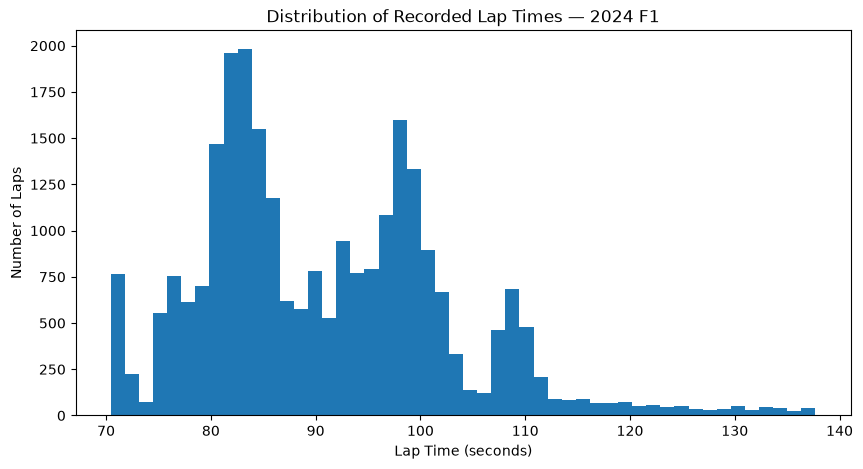

In [19]:
plt.figure(figsize=(10, 5))

plt.hist(
    analysis_laps["LapTimeSeconds"],
    bins=50
)

plt.xlabel("Lap Time (seconds)")
plt.ylabel("Number of Laps")
plt.title("Distribution of Recorded Lap Times — 2024 F1")

plt.show()

In [20]:
results_analysis = results.copy()

results_analysis["Position"] = pd.to_numeric(
    results_analysis["Position"],
    errors="coerce"
)

results_analysis = results_analysis.dropna(
    subset=["FullName", "Position"]
)

print("Valid race-result rows:", len(results_analysis))

Valid race-result rows: 479


In [21]:
laps["LapTime"] = pd.to_timedelta(
    laps["LapTime"],
    errors="coerce"
)

laps["LapTimeSeconds"] = (
    laps["LapTime"].dt.total_seconds()
)

clean_laps = laps.dropna(
    subset=[
        "EventName",
        "Driver",
        "LapNumber",
        "LapTimeSeconds"
    ]
).copy()

low = clean_laps["LapTimeSeconds"].quantile(0.01)
high = clean_laps["LapTimeSeconds"].quantile(0.99)

analysis_laps = clean_laps[
    clean_laps["LapTimeSeconds"].between(low, high)
].copy()

print("Raw lap rows:", len(laps))
print("Clean lap rows:", len(clean_laps))
print("Analysis lap rows:", len(analysis_laps))

Raw lap rows: 26604
Clean lap rows: 26381
Analysis lap rows: 25853


In [22]:
results_analysis = results.copy()

results_analysis["Position"] = pd.to_numeric(
    results_analysis["Position"],
    errors="coerce"
)

results_analysis = results_analysis.dropna(
    subset=["FullName", "Position"]
)

print("Valid race-result rows:", len(results_analysis))

Valid race-result rows: 479


In [23]:
finish_summary = (
    results_analysis
    .groupby("FullName", as_index=False)
    .agg(
        races=("Position", "count"),
        avg_finish=("Position", "mean"),
        points=("Points", "sum")
    )
    .sort_values("avg_finish")
)

display(finish_summary.head(15))

,FullName,races,avg_finish,points
16,Max Verstappen,24,3.625000,399.0
12,Lando Norris,24,4.291667,344.0
2,Charles Leclerc,24,4.541667,327.0
19,Oscar Piastri,24,5.125000,265.0
1,Carlos Sainz,23,5.695652,262.0
7,George Russell,24,6.750000,226.0
13,Lewis Hamilton,24,6.958333,207.0
21,Sergio Perez,24,9.625000,138.0
18,Oliver Bearman,3,9.666667,7.0
5,Fernando Alonso,24,10.166667,70.0


In [24]:
finish_summary_display = finish_summary.copy()

finish_summary_display["avg_finish"] = (
    finish_summary_display["avg_finish"]
    .round(2)
)

finish_summary_display["points"] = (
    finish_summary_display["points"]
    .round(1)
)

display(finish_summary_display.head(15))

,FullName,races,avg_finish,points
16,Max Verstappen,24,3.62,399.0
12,Lando Norris,24,4.29,344.0
2,Charles Leclerc,24,4.54,327.0
19,Oscar Piastri,24,5.12,265.0
1,Carlos Sainz,23,5.70,262.0
7,George Russell,24,6.75,226.0
13,Lewis Hamilton,24,6.96,207.0
21,Sergio Perez,24,9.62,138.0
18,Oliver Bearman,3,9.67,7.0
5,Fernando Alonso,24,10.17,70.0


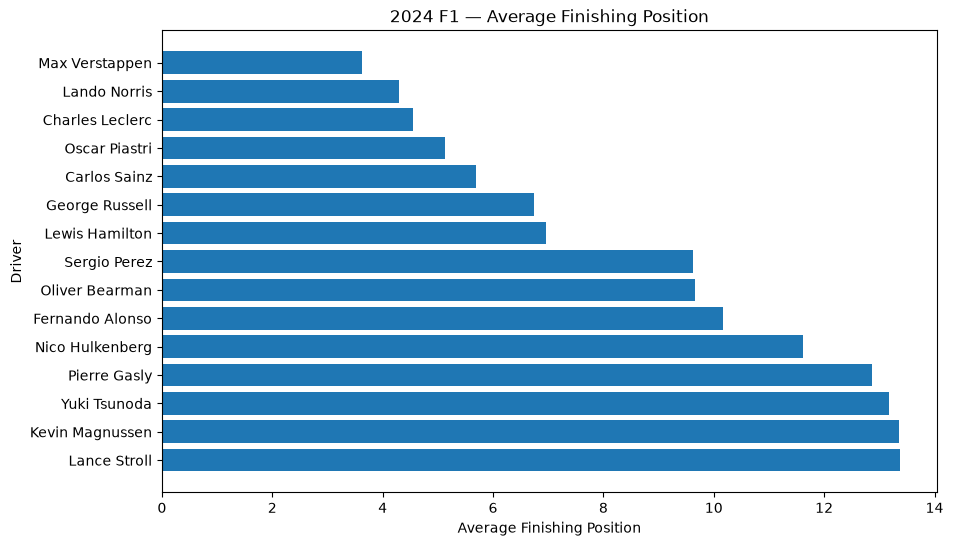

In [25]:
top_finishers = (
    finish_summary
    .head(15)
    .sort_values("avg_finish", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_finishers["FullName"],
    top_finishers["avg_finish"]
)

plt.gca().invert_yaxis()

plt.xlabel("Average Finishing Position")
plt.ylabel("Driver")
plt.title("2024 F1 — Average Finishing Position")

plt.show()

## Analysis 1 — Average Finishing Position

Average finishing position was calculated from the recorded race-result data.

The analysis shows variation in finishing outcomes across drivers during the 2024 season. However, average finishing position should not be interpreted as a pure measure of driver ability because race results are also influenced by car performance, strategy, reliability, pit stops, incidents, and race conditions.

The number of recorded race results also varies between drivers, so drivers with substantially fewer observations should be interpreted with caution.

In [26]:
lap_pace_summary = (
    analysis_laps
    .groupby("Driver", as_index=False)
    .agg(
        laps=("LapTimeSeconds", "count"),
        mean_lap_time=("LapTimeSeconds", "mean"),
        median_lap_time=("LapTimeSeconds", "median"),
        lap_time_std=("LapTimeSeconds", "std")
    )
    .sort_values("mean_lap_time")
)

display(lap_pace_summary)

,Driver,laps,mean_lap_time,median_lap_time,lap_time_std
19,SAR,756,89.809357,86.0600,12.260560
12,NOR,1370,90.137077,88.0170,11.410778
16,RIC,986,90.152944,85.7650,12.481414
10,LEC,1358,90.224137,88.4820,11.259950
7,HAM,1297,90.281518,87.7330,11.757057
22,VER,1318,90.348172,89.0970,11.361509
15,PIA,1386,90.349241,87.9705,11.654076
18,SAI,1288,90.357766,88.0655,11.596967
17,RUS,1360,90.439176,88.3300,11.579607
6,GAS,1231,90.667946,86.6580,12.321471


In [27]:
lap_pace_display = lap_pace_summary.copy()

lap_pace_display["mean_lap_time"] = (
    lap_pace_display["mean_lap_time"].round(3)
)

lap_pace_display["median_lap_time"] = (
    lap_pace_display["median_lap_time"].round(3)
)

lap_pace_display["lap_time_std"] = (
    lap_pace_display["lap_time_std"].round(3)
)

display(lap_pace_display)

,Driver,laps,mean_lap_time,median_lap_time,lap_time_std
19,SAR,756,89.809,86.060,12.261
12,NOR,1370,90.137,88.017,11.411
16,RIC,986,90.153,85.765,12.481
10,LEC,1358,90.224,88.482,11.260
7,HAM,1297,90.282,87.733,11.757
22,VER,1318,90.348,89.097,11.362
15,PIA,1386,90.349,87.970,11.654
18,SAI,1288,90.358,88.066,11.597
17,RUS,1360,90.439,88.330,11.580
6,GAS,1231,90.668,86.658,12.321


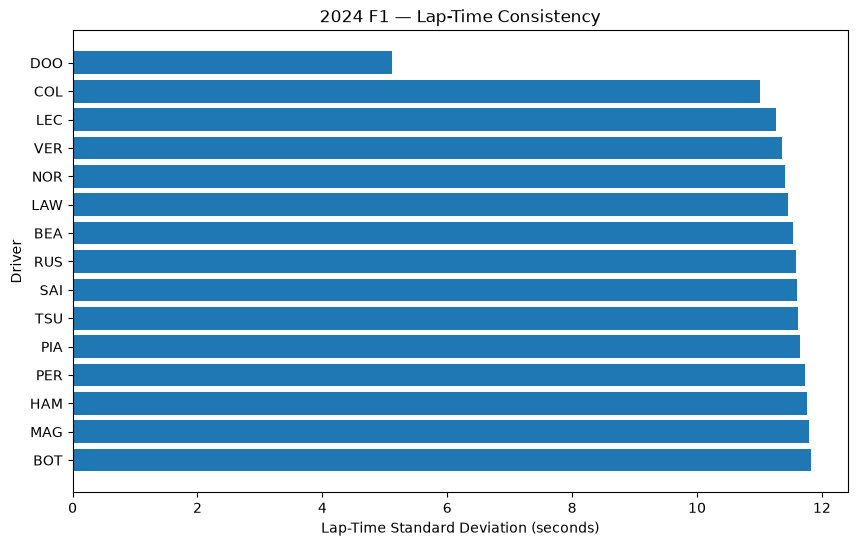

In [28]:
consistency = (
    lap_pace_summary
    .sort_values("lap_time_std")
    .head(15)
)

plt.figure(figsize=(10, 6))

plt.barh(
    consistency["Driver"],
    consistency["lap_time_std"]
)

plt.gca().invert_yaxis()

plt.xlabel("Lap-Time Standard Deviation (seconds)")
plt.ylabel("Driver")
plt.title("2024 F1 — Lap-Time Consistency")

plt.show()

In [29]:
results_points = results.copy()

results_points["Points"] = pd.to_numeric(
    results_points["Points"],
    errors="coerce"
).fillna(0)

print("Total points recorded:", results_points["Points"].sum())

Total points recorded: 2443.0


In [30]:
points_summary = (
    results_points
    .groupby("FullName", as_index=False)
    .agg(
        points=("Points", "sum")
    )
    .sort_values("points", ascending=False)
)

display(points_summary)

,FullName,points
16,Max Verstappen,399.0
12,Lando Norris,344.0
2,Charles Leclerc,327.0
19,Oscar Piastri,265.0
1,Carlos Sainz,262.0
7,George Russell,226.0
13,Lewis Hamilton,207.0
21,Sergio Perez,138.0
5,Fernando Alonso,70.0
20,Pierre Gasly,40.0


In [31]:
points_display = points_summary.copy()

points_display["points"] = (
    points_display["points"].round(1)
)

display(points_display)

,FullName,points
16,Max Verstappen,399.0
12,Lando Norris,344.0
2,Charles Leclerc,327.0
19,Oscar Piastri,265.0
1,Carlos Sainz,262.0
7,George Russell,226.0
13,Lewis Hamilton,207.0
21,Sergio Perez,138.0
5,Fernando Alonso,70.0
20,Pierre Gasly,40.0


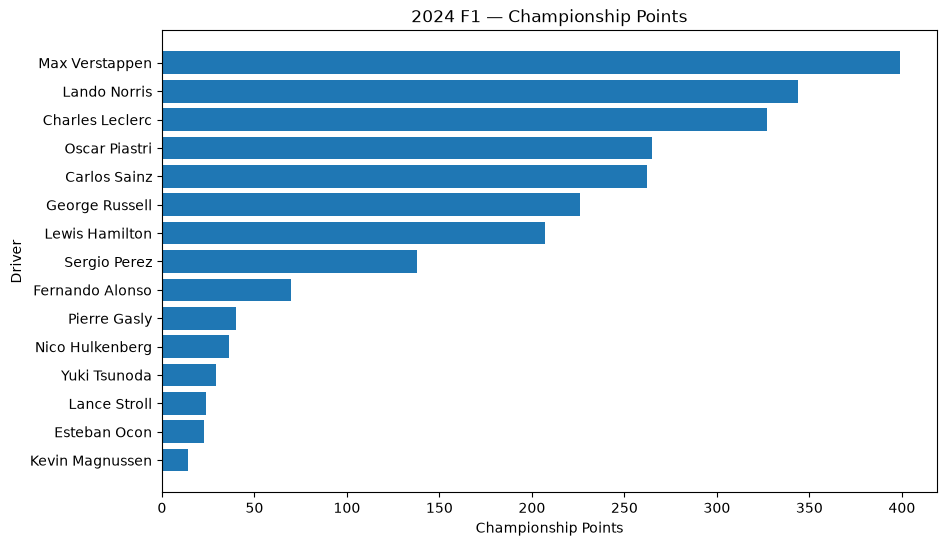

In [32]:
points_plot = (
    points_summary
    .head(15)
    .sort_values("points", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    points_plot["FullName"],
    points_plot["points"]
)

plt.xlabel("Championship Points")
plt.ylabel("Driver")
plt.title("2024 F1 — Championship Points")

plt.show()

In [33]:
relative_laps = analysis_laps.copy()

# Normalize event names
relative_laps["EventName"] = (
    relative_laps["EventName"]
    .astype(str)
    .str.strip()
)

print("Rows:", len(relative_laps))
print("Races:", relative_laps["EventName"].nunique())

Rows: 25853
Races: 24


In [34]:
race_lap_median = (
    relative_laps
    .groupby(
        ["EventName", "LapNumber"],
        as_index=False
    )["LapTimeSeconds"]
    .median()
    .rename(
        columns={
            "LapTimeSeconds": "RaceLapMedian"
        }
    )
)

display(race_lap_median.head(10))

,EventName,LapNumber,RaceLapMedian
0,Abu Dhabi Grand Prix,1.0,99.017
1,Abu Dhabi Grand Prix,2.0,114.148
2,Abu Dhabi Grand Prix,3.0,99.656
3,Abu Dhabi Grand Prix,4.0,89.666
4,Abu Dhabi Grand Prix,5.0,89.968
5,Abu Dhabi Grand Prix,6.0,89.997
6,Abu Dhabi Grand Prix,7.0,90.034
7,Abu Dhabi Grand Prix,8.0,90.089
8,Abu Dhabi Grand Prix,9.0,89.959
9,Abu Dhabi Grand Prix,10.0,90.449


In [35]:
relative_laps = relative_laps.merge(
    race_lap_median,
    on=["EventName", "LapNumber"],
    how="left"
)

print("Rows after merge:", len(relative_laps))

display(
    relative_laps[
        [
            "EventName",
            "Driver",
            "LapNumber",
            "LapTimeSeconds",
            "RaceLapMedian"
        ]
    ].head(10)
)

Rows after merge: 25853


,EventName,Driver,LapNumber,LapTimeSeconds,RaceLapMedian
0,Bahrain Grand Prix,VER,1.0,97.284,103.6865
1,Bahrain Grand Prix,VER,2.0,96.296,98.3275
2,Bahrain Grand Prix,VER,3.0,96.753,98.3510
3,Bahrain Grand Prix,VER,4.0,96.647,98.2985
4,Bahrain Grand Prix,VER,5.0,97.173,98.4295
5,Bahrain Grand Prix,VER,6.0,97.092,98.2720
6,Bahrain Grand Prix,VER,7.0,97.038,98.5090
7,Bahrain Grand Prix,VER,8.0,97.024,98.3670
8,Bahrain Grand Prix,VER,9.0,97.229,98.6485
9,Bahrain Grand Prix,VER,10.0,96.960,98.7470


In [36]:
relative_laps["RelativeLapTime"] = (
    relative_laps["LapTimeSeconds"]
    - relative_laps["RaceLapMedian"]
)

display(
    relative_laps[
        [
            "EventName",
            "Driver",
            "LapNumber",
            "LapTimeSeconds",
            "RaceLapMedian",
            "RelativeLapTime"
        ]
    ].head(10)
)

,EventName,Driver,LapNumber,LapTimeSeconds,RaceLapMedian,RelativeLapTime
0,Bahrain Grand Prix,VER,1.0,97.284,103.6865,-6.4025
1,Bahrain Grand Prix,VER,2.0,96.296,98.3275,-2.0315
2,Bahrain Grand Prix,VER,3.0,96.753,98.3510,-1.5980
3,Bahrain Grand Prix,VER,4.0,96.647,98.2985,-1.6515
4,Bahrain Grand Prix,VER,5.0,97.173,98.4295,-1.2565
5,Bahrain Grand Prix,VER,6.0,97.092,98.2720,-1.1800
6,Bahrain Grand Prix,VER,7.0,97.038,98.5090,-1.4710
7,Bahrain Grand Prix,VER,8.0,97.024,98.3670,-1.3430
8,Bahrain Grand Prix,VER,9.0,97.229,98.6485,-1.4195
9,Bahrain Grand Prix,VER,10.0,96.960,98.7470,-1.7870


In [37]:
relative_pace_summary = (
    relative_laps
    .groupby("Driver", as_index=False)
    .agg(
        laps=("RelativeLapTime", "count"),
        mean_relative_pace=("RelativeLapTime", "mean"),
        median_relative_pace=("RelativeLapTime", "median"),
        std_relative_pace=("RelativeLapTime", "std")
    )
    .sort_values("mean_relative_pace")
)

display(relative_pace_summary)

,Driver,laps,mean_relative_pace,median_relative_pace,std_relative_pace
22,VER,1318,-0.529144,-0.91500,3.792842
12,NOR,1370,-0.502548,-0.93825,3.844476
10,LEC,1358,-0.288307,-0.71250,3.565255
18,SAI,1288,-0.220734,-0.67600,3.237300
15,PIA,1386,-0.169998,-0.66650,3.421190
17,RUS,1360,-0.057159,-0.54925,3.382812
7,HAM,1297,0.004150,-0.49350,3.599122
14,PER,1233,0.255364,-0.32250,3.670193
2,BEA,164,0.336899,0.04175,3.531955
1,ALO,1355,0.663834,0.02500,3.241768


In [38]:
controlled_laps = analysis_laps.copy()

controlled_laps["EventName"] = (
    controlled_laps["EventName"]
    .astype(str)
    .str.strip()
)

print("Rows:", len(controlled_laps))

Rows: 25853


In [39]:
controlled_laps = controlled_laps[
    controlled_laps["PitOutTime"].isna()
    & controlled_laps["PitInTime"].isna()
].copy()

print("Rows after excluding pit laps:", len(controlled_laps))

Rows after excluding pit laps: 24399


In [40]:
lap_driver_counts = (
    controlled_laps
    .groupby(["EventName", "LapNumber"])["Driver"]
    .nunique()
)

print(lap_driver_counts.describe())

count    1430.000000
mean       17.062238
std         2.764549
min         1.000000
25%        16.000000
50%        18.000000
75%        19.000000
max        20.000000
Name: Driver, dtype: float64


In [41]:
valid_lap_groups = lap_driver_counts[
    lap_driver_counts >= 5
].index

controlled_laps = (
    controlled_laps
    .set_index(["EventName", "LapNumber"])
    .loc[valid_lap_groups]
    .reset_index()
)

print("Comparable lap observations:", len(controlled_laps))

Comparable lap observations: 24367


In [42]:
def leave_one_out_median(group):
    times = group["LapTimeSeconds"].to_numpy()
    drivers = group["Driver"].to_numpy()

    result = []

    for i in range(len(times)):
        other_times = np.delete(times, i)

        result.append(
            np.median(other_times)
        )

    group = group.copy()
    group["OtherDriverMedian"] = result

    return group

In [43]:
controlled_laps = (
    controlled_laps
    .groupby(
        ["EventName", "LapNumber"],
        group_keys=False
    )
    .apply(leave_one_out_median)
    .reset_index(drop=True)
)

print("Rows:", len(controlled_laps))

Rows: 24367


C:\Users\User\AppData\Local\Temp\ipykernel_952\2205863110.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(leave_one_out_median)


In [44]:
controlled_laps["RelativeLapTime"] = (
    controlled_laps["LapTimeSeconds"]
    - controlled_laps["OtherDriverMedian"]
)

display(
    controlled_laps[
        [
            "EventName",
            "Driver",
            "LapNumber",
            "LapTimeSeconds",
            "OtherDriverMedian",
            "RelativeLapTime"
        ]
    ].head(10)
)

,EventName,Driver,LapNumber,LapTimeSeconds,OtherDriverMedian,RelativeLapTime
0,Abu Dhabi Grand Prix,VER,1.0,99.510,98.6705,0.8395
1,Abu Dhabi Grand Prix,GAS,1.0,93.984,99.2635,-5.2795
2,Abu Dhabi Grand Prix,ALO,1.0,96.166,99.2635,-3.0975
3,Abu Dhabi Grand Prix,LEC,1.0,97.644,99.2635,-1.6195
4,Abu Dhabi Grand Prix,STR,1.0,98.324,99.2635,-0.9395
5,Abu Dhabi Grand Prix,MAG,1.0,96.949,99.2635,-2.3145
6,Abu Dhabi Grand Prix,TSU,1.0,102.007,98.6705,3.3365
7,Abu Dhabi Grand Prix,ALB,1.0,101.190,98.6705,2.5195
8,Abu Dhabi Grand Prix,ZHO,1.0,100.718,98.6705,2.0475
9,Abu Dhabi Grand Prix,HUL,1.0,95.498,99.2635,-3.7655


In [45]:
controlled_relative_pace = (
    controlled_laps
    .groupby("Driver", as_index=False)
    .agg(
        laps=("RelativeLapTime", "count"),
        mean_relative_pace=("RelativeLapTime", "mean"),
        median_relative_pace=("RelativeLapTime", "median"),
        std_relative_pace=("RelativeLapTime", "std")
    )
    .sort_values("mean_relative_pace")
)

display(controlled_relative_pace)

,Driver,laps,mean_relative_pace,median_relative_pace,std_relative_pace
12,NOR,1298,-1.031305,-1.00900,2.041412
22,VER,1252,-0.997632,-0.98775,2.210170
10,LEC,1287,-0.759907,-0.75000,1.738288
18,SAI,1218,-0.724706,-0.72550,1.694350
15,PIA,1311,-0.664836,-0.72400,1.973565
17,RUS,1286,-0.582527,-0.61300,1.668239
7,HAM,1221,-0.551445,-0.56300,1.792770
14,PER,1152,-0.352082,-0.40675,1.718070
2,BEA,159,0.164173,0.13200,3.114934
1,ALO,1278,0.196099,0.09025,1.510185


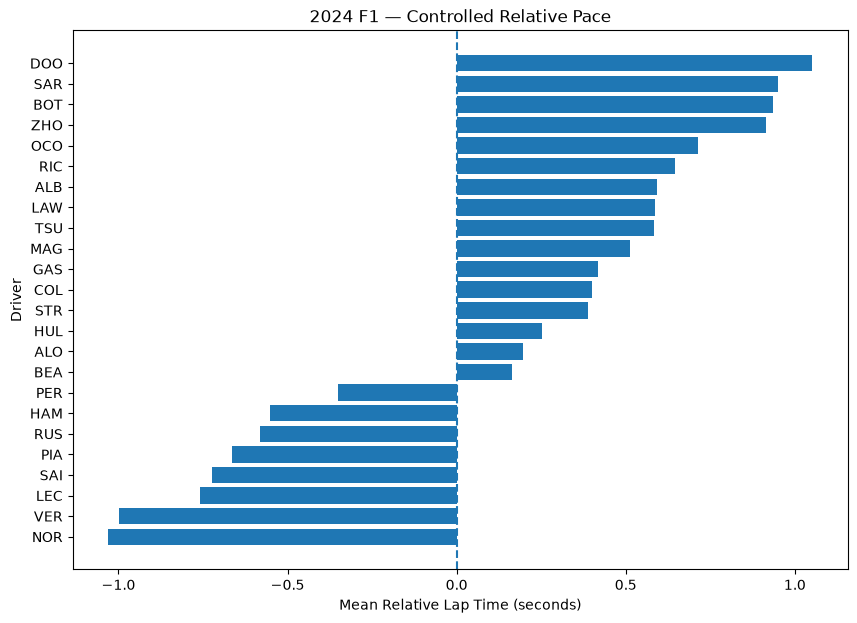

In [46]:
relative_plot = (
    controlled_relative_pace
    .sort_values("mean_relative_pace")
)

plt.figure(figsize=(10, 7))

plt.barh(
    relative_plot["Driver"],
    relative_plot["mean_relative_pace"]
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel("Mean Relative Lap Time (seconds)")
plt.ylabel("Driver")
plt.title("2024 F1 — Controlled Relative Pace")

plt.show()

In [47]:
controlled_relative_pace.to_csv(
    PROCESSED_DIR / "controlled_relative_pace_summary.csv",
    index=False
)

print("Saved:")
print(
    PROCESSED_DIR /
    "controlled_relative_pace_summary.csv"
)

Saved:
C:\Users\User\Latihan\.vscode\Project_1_F1_Motorsport_Race_Analysis\data\processed\controlled_relative_pace_summary.csv


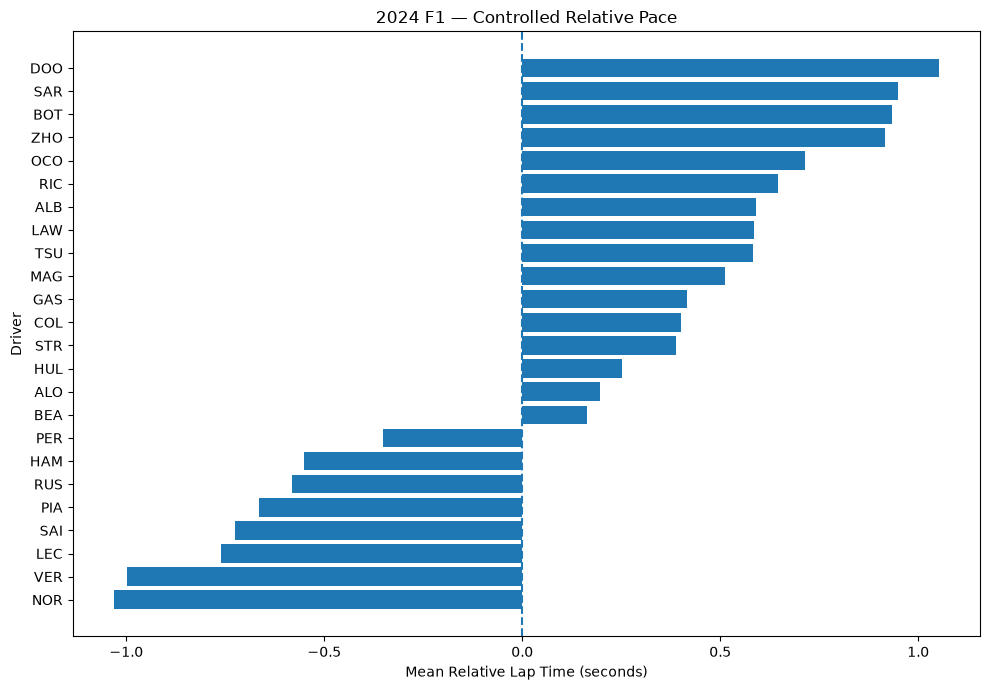

In [48]:
plt.figure(figsize=(10, 7))

relative_plot = (
    controlled_relative_pace
    .sort_values("mean_relative_pace")
)

plt.barh(
    relative_plot["Driver"],
    relative_plot["mean_relative_pace"]
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel("Mean Relative Lap Time (seconds)")
plt.ylabel("Driver")
plt.title("2024 F1 — Controlled Relative Pace")

plt.tight_layout()

plt.savefig(
    FIG_DIR / "06_controlled_relative_pace.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [49]:
race_relative_pace = (
    controlled_laps
    .groupby(["EventName", "Driver"], as_index=False)
    .agg(
        laps=("RelativeLapTime", "count"),
        mean_relative_pace=("RelativeLapTime", "mean"),
        median_relative_pace=("RelativeLapTime", "median"),
        std_relative_pace=("RelativeLapTime", "std")
    )
)

display(race_relative_pace.head(20))

,EventName,Driver,laps,mean_relative_pace,median_relative_pace,std_relative_pace
0,Abu Dhabi Grand Prix,ALB,55,0.804791,0.50400,1.307756
1,Abu Dhabi Grand Prix,ALO,54,-0.107269,-0.11425,0.975398
2,Abu Dhabi Grand Prix,BOT,27,0.299944,0.01700,1.043988
3,Abu Dhabi Grand Prix,COL,23,0.900957,0.20950,1.944239
4,Abu Dhabi Grand Prix,DOO,55,1.051809,0.87400,1.174259
5,Abu Dhabi Grand Prix,GAS,56,0.252688,0.25850,1.281610
6,Abu Dhabi Grand Prix,HAM,56,-0.439625,-0.25750,0.867185
7,Abu Dhabi Grand Prix,HUL,56,0.311348,0.11975,1.153549
8,Abu Dhabi Grand Prix,LAW,50,0.516290,0.43950,0.621624
9,Abu Dhabi Grand Prix,LEC,56,-0.529286,-0.48700,0.514311


In [50]:
race_relative_pace.to_csv(
    PROCESSED_DIR / "race_driver_relative_pace.csv",
    index=False
)

print("Saved:")
print(PROCESSED_DIR / "race_driver_relative_pace.csv")

Saved:
C:\Users\User\Latihan\.vscode\Project_1_F1_Motorsport_Race_Analysis\data\processed\race_driver_relative_pace.csv


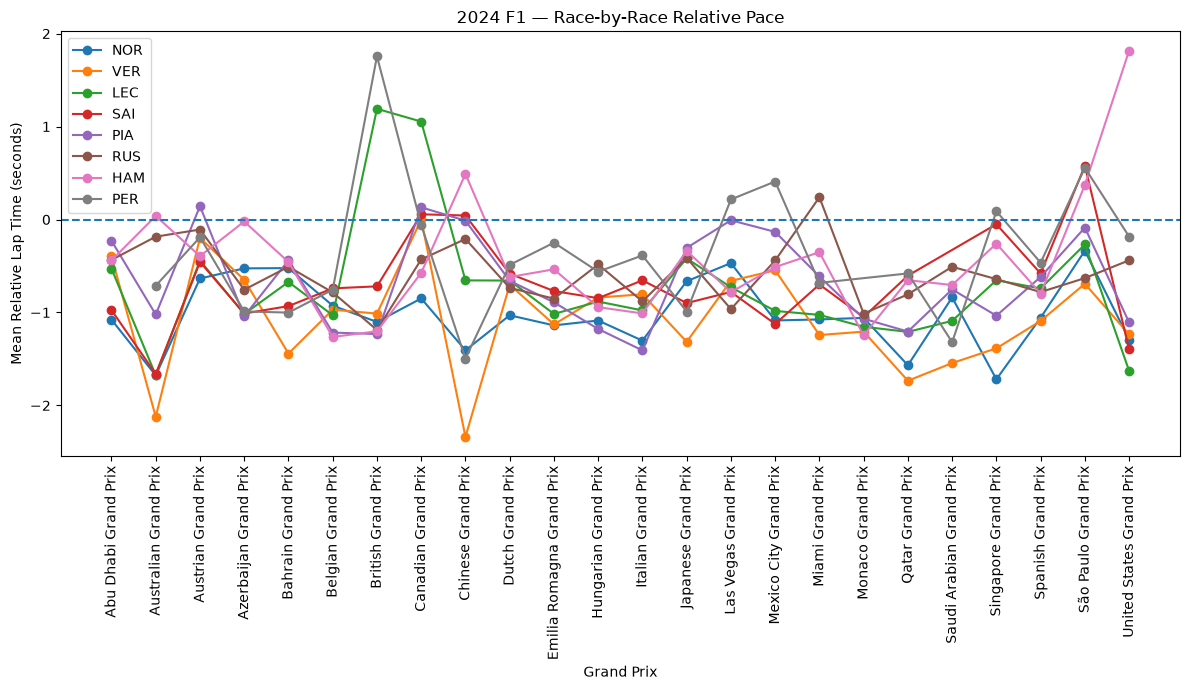

In [51]:
top_drivers = (
    controlled_relative_pace
    .sort_values("mean_relative_pace")
    .head(8)["Driver"]
    .tolist()
)

plot_data = race_relative_pace[
    race_relative_pace["Driver"].isin(top_drivers)
]

plt.figure(figsize=(12, 7))

for driver in top_drivers:
    driver_data = plot_data[
        plot_data["Driver"] == driver
    ]

    plt.plot(
        driver_data["EventName"],
        driver_data["mean_relative_pace"],
        marker="o",
        label=driver
    )

plt.axhline(0, linestyle="--")

plt.xlabel("Grand Prix")
plt.ylabel("Mean Relative Lap Time (seconds)")
plt.title("2024 F1 — Race-by-Race Relative Pace")

plt.xticks(rotation=90)
plt.legend()

plt.tight_layout()

plt.savefig(
    FIG_DIR / "07_race_by_race_relative_pace.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

In [52]:
print("Lap columns:")
print(controlled_laps.columns.tolist())

Lap columns:
['EventName', 'LapNumber', 'Year', 'RoundNumber', 'Driver', 'DriverNumber', 'Team', 'LapTime', 'Stint', 'Compound', 'TyreLife', 'FreshTyre', 'TrackStatus', 'PitOutTime', 'PitInTime', 'IsPersonalBest', 'LapTimeSeconds', 'OtherDriverMedian', 'RelativeLapTime']


In [53]:
print("Unique tyre compounds:")
print(controlled_laps["Compound"].dropna().unique())

print("\nTyreLife range:")
print(
    controlled_laps["TyreLife"]
    .dropna()
    .describe()
)

Unique tyre compounds:
['MEDIUM' 'HARD' 'SOFT' 'INTERMEDIATE' 'WET']

TyreLife range:
count    24367.000000
mean        15.476874
std         11.215035
min          1.000000
25%          7.000000
50%         13.000000
75%         21.000000
max         78.000000
Name: TyreLife, dtype: float64


In [54]:
tyre_age_relative_pace = (
    controlled_laps
    .dropna(subset=["Compound", "TyreLife", "RelativeLapTime"])
    .groupby(["Compound", "TyreLife"], as_index=False)
    .agg(
        laps=("RelativeLapTime", "count"),
        mean_relative_pace=("RelativeLapTime", "mean"),
        median_relative_pace=("RelativeLapTime", "median"),
        std_relative_pace=("RelativeLapTime", "std")
    )
)

display(
    tyre_age_relative_pace.head(30)
)

,Compound,TyreLife,laps,mean_relative_pace,median_relative_pace,std_relative_pace
0,HARD,1.0,30,3.060600,3.63125,2.889898
1,HARD,2.0,384,-0.299987,-0.50250,2.190800
2,HARD,3.0,453,-0.362810,-0.35800,1.400543
3,HARD,4.0,466,-0.287837,-0.31075,1.473263
4,HARD,5.0,455,-0.499560,-0.26100,2.307544
5,HARD,6.0,458,-0.329659,-0.21900,1.375602
6,HARD,7.0,454,-0.303801,-0.21950,1.206083
7,HARD,8.0,459,-0.221927,-0.11200,1.845802
8,HARD,9.0,466,-0.177218,-0.11000,1.161001
9,HARD,10.0,464,-0.086697,-0.10325,1.357131


In [55]:
tyre_age_relative_pace_filtered = (
    tyre_age_relative_pace[
        tyre_age_relative_pace["laps"] >= 20
    ]
    .copy()
)

print(
    "Rows after minimum 20 laps:",
    len(tyre_age_relative_pace_filtered)
)

display(
    tyre_age_relative_pace_filtered.head(30)
)

Rows after minimum 20 laps: 135


,Compound,TyreLife,laps,mean_relative_pace,median_relative_pace,std_relative_pace
0,HARD,1.0,30,3.060600,3.63125,2.889898
1,HARD,2.0,384,-0.299987,-0.50250,2.190800
2,HARD,3.0,453,-0.362810,-0.35800,1.400543
3,HARD,4.0,466,-0.287837,-0.31075,1.473263
4,HARD,5.0,455,-0.499560,-0.26100,2.307544
5,HARD,6.0,458,-0.329659,-0.21900,1.375602
6,HARD,7.0,454,-0.303801,-0.21950,1.206083
7,HARD,8.0,459,-0.221927,-0.11200,1.845802
8,HARD,9.0,466,-0.177218,-0.11000,1.161001
9,HARD,10.0,464,-0.086697,-0.10325,1.357131


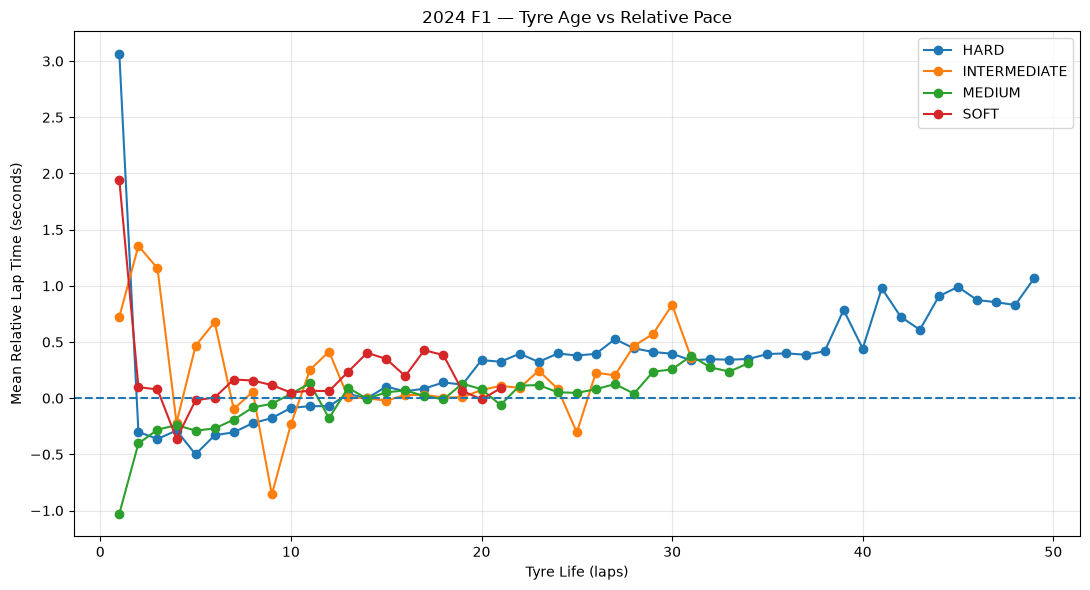

In [56]:
plt.figure(figsize=(11, 6))

for compound in tyre_age_relative_pace_filtered["Compound"].unique():

    compound_data = tyre_age_relative_pace_filtered[
        tyre_age_relative_pace_filtered["Compound"] == compound
    ]

    plt.plot(
        compound_data["TyreLife"],
        compound_data["mean_relative_pace"],
        marker="o",
        label=compound
    )

plt.axhline(0, linestyle="--")

plt.xlabel("Tyre Life (laps)")
plt.ylabel("Mean Relative Lap Time (seconds)")
plt.title("2024 F1 — Tyre Age vs Relative Pace")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [57]:
tyre_age_relative_pace_filtered.to_csv(
    PROCESSED_DIR / "tyre_age_relative_pace_summary.csv",
    index=False
)

print("Saved:")
print(
    PROCESSED_DIR /
    "tyre_age_relative_pace_summary.csv"
)

Saved:
C:\Users\User\Latihan\.vscode\Project_1_F1_Motorsport_Race_Analysis\data\processed\tyre_age_relative_pace_summary.csv


In [58]:
tyre_summary = (
    controlled_laps
    .groupby(["Compound", "TyreLife"], as_index=False)
    .agg(
        laps=("RelativeLapTime", "count"),
        mean_relative_pace=("RelativeLapTime", "mean"),
        median_relative_pace=("RelativeLapTime", "median"),
        std_relative_pace=("RelativeLapTime", "std")
    )
)

# Hanya gunakan TyreLife dengan minimal 20 lap
tyre_summary = tyre_summary[
    tyre_summary["laps"] >= 20
].copy()

display(tyre_summary.head(30))

,Compound,TyreLife,laps,mean_relative_pace,median_relative_pace,std_relative_pace
0,HARD,1.0,30,3.060600,3.63125,2.889898
1,HARD,2.0,384,-0.299987,-0.50250,2.190800
2,HARD,3.0,453,-0.362810,-0.35800,1.400543
3,HARD,4.0,466,-0.287837,-0.31075,1.473263
4,HARD,5.0,455,-0.499560,-0.26100,2.307544
5,HARD,6.0,458,-0.329659,-0.21900,1.375602
6,HARD,7.0,454,-0.303801,-0.21950,1.206083
7,HARD,8.0,459,-0.221927,-0.11200,1.845802
8,HARD,9.0,466,-0.177218,-0.11000,1.161001
9,HARD,10.0,464,-0.086697,-0.10325,1.357131


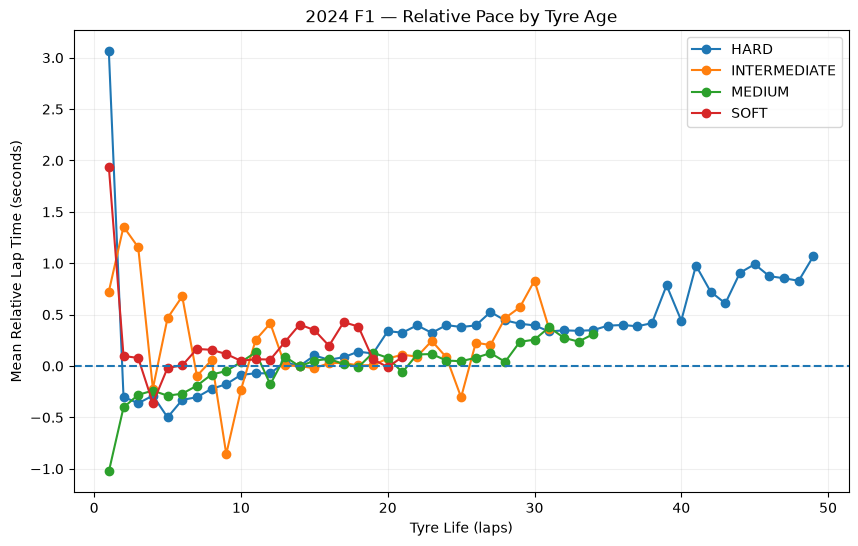

In [59]:
plt.figure(figsize=(10, 6))

for compound in tyre_summary["Compound"].unique():
    compound_data = tyre_summary[
        tyre_summary["Compound"] == compound
    ]

    plt.plot(
        compound_data["TyreLife"],
        compound_data["mean_relative_pace"],
        marker="o",
        label=compound
    )

plt.axhline(0, linestyle="--")

plt.xlabel("Tyre Life (laps)")
plt.ylabel("Mean Relative Lap Time (seconds)")
plt.title("2024 F1 — Relative Pace by Tyre Age")

plt.legend()
plt.grid(alpha=0.2)

plt.savefig(
    FIG_DIR / "10_controlled_tyre_age_relative_pace.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

In [60]:
weighted_results = []

for compound in tyre_summary["Compound"].unique():

    compound_data = tyre_summary[
        tyre_summary["Compound"] == compound
    ].copy()

    x = compound_data["TyreLife"].to_numpy()
    y = compound_data["mean_relative_pace"].to_numpy()
    weights = compound_data["laps"].to_numpy()

    if len(compound_data) < 2:
        continue

    # Weighted linear regression
    slope, intercept = np.polyfit(
        x,
        y,
        1,
        w=np.sqrt(weights)
    )

    # Weighted correlation
    weighted_mean_x = np.average(x, weights=weights)
    weighted_mean_y = np.average(y, weights=weights)

    covariance = np.average(
        (x - weighted_mean_x) * (y - weighted_mean_y),
        weights=weights
    )

    variance_x = np.average(
        (x - weighted_mean_x) ** 2,
        weights=weights
    )

    variance_y = np.average(
        (y - weighted_mean_y) ** 2,
        weights=weights
    )

    weighted_corr = covariance / np.sqrt(
        variance_x * variance_y
    )

    weighted_results.append({
        "Compound": compound,
        "TyreLife_points": len(compound_data),
        "total_laps": weights.sum(),
        "slope_seconds_per_lap": slope,
        "intercept": intercept,
        "weighted_correlation": weighted_corr,
        "min_TyreLife": x.min(),
        "max_TyreLife": x.max()
    })

weighted_degradation = pd.DataFrame(weighted_results)

display(weighted_degradation)

,Compound,TyreLife_points,total_laps,slope_seconds_per_lap,intercept,weighted_correlation,min_TyreLife,max_TyreLife
0,HARD,49,12386,0.027272,-0.379938,0.819778,1.0,49.0
1,INTERMEDIATE,31,1854,-0.012846,0.361816,-0.218384,1.0,31.0
2,MEDIUM,34,7898,0.022442,-0.368386,0.747272,1.0,34.0
3,SOFT,21,1545,0.003838,0.110948,0.057719,1.0,21.0


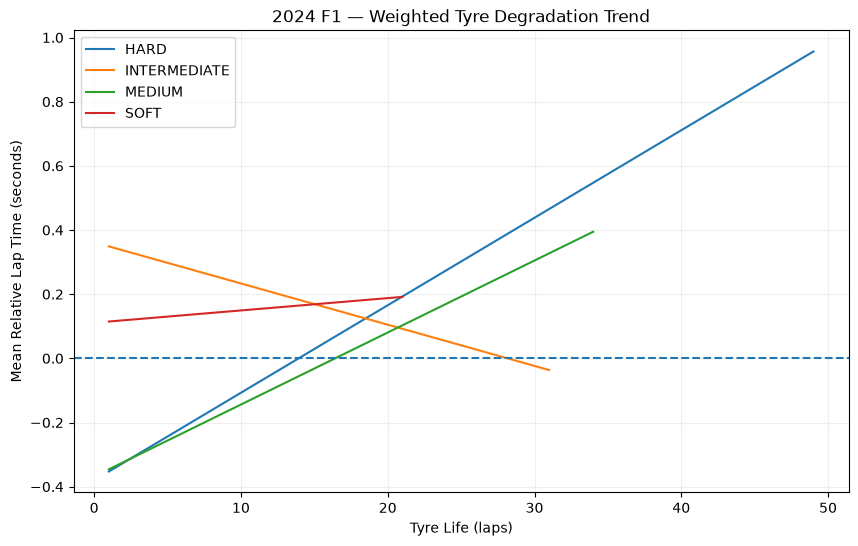

In [61]:
plt.figure(figsize=(10, 6))

for compound in tyre_summary["Compound"].unique():

    compound_data = tyre_summary[
        tyre_summary["Compound"] == compound
    ].copy()

    if len(compound_data) < 2:
        continue

    x = compound_data["TyreLife"].to_numpy()
    y = compound_data["mean_relative_pace"].to_numpy()
    weights = compound_data["laps"].to_numpy()

    slope, intercept = np.polyfit(
        x,
        y,
        1,
        w=np.sqrt(weights)
    )

    x_line = np.linspace(
        x.min(),
        x.max(),
        100
    )

    y_line = intercept + slope * x_line

    plt.plot(
        x_line,
        y_line,
        label=compound
    )

plt.axhline(0, linestyle="--")

plt.xlabel("Tyre Life (laps)")
plt.ylabel("Mean Relative Lap Time (seconds)")
plt.title("2024 F1 — Weighted Tyre Degradation Trend")

plt.legend()
plt.grid(alpha=0.2)

plt.savefig(
    FIG_DIR / "12_weighted_tyre_degradation_trend.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

In [62]:
weighted_degradation.to_csv(
    PROCESSED_DIR / "weighted_tyre_degradation_trend.csv",
    index=False
)

print("Saved:")
print(PROCESSED_DIR / "weighted_tyre_degradation_trend.csv")

Saved:
C:\Users\User\Latihan\.vscode\Project_1_F1_Motorsport_Race_Analysis\data\processed\weighted_tyre_degradation_trend.csv


# Key Findings

## 1. Driver Relative Pace

The controlled relative-pace analysis compares each driver's lap time with the median lap time of the other drivers on the same race and lap.

The results show differences in relative pace across drivers. In this dataset, NOR and VER have the lowest mean relative lap times, while several drivers have positive mean relative lap times.

These results describe relative pace within the analyzed observations and should not be interpreted as a standalone measure of driver skill or overall performance.

## 2. Race-by-Race Pace

Relative pace varies across different Grand Prix events.

The race-by-race analysis shows that a driver's relative pace is not constant throughout the season. Differences between races may reflect circuit characteristics, weather, tyre usage, traffic, strategy, car performance, and other race conditions.

## 3. Tyre Age

The tyre-age analysis shows a general increase in relative lap time for older HARD and MEDIUM tyres.

For example, HARD tyres move from mostly negative relative pace at lower tyre ages toward positive relative pace at higher tyre ages.

This pattern is consistent with an association between increasing tyre age and slower relative lap times.

## 4. Weighted Tyre Degradation Trend

The weighted regression provides an exploratory summary of the relationship between tyre age and relative lap time.

HARD and MEDIUM tyres show positive slopes and relatively strong positive weighted correlations in this dataset.

SOFT tyres show only a weak linear relationship, while INTERMEDIATE tyres show a negative relationship. The latter should be interpreted cautiously because intermediate tyres are used under changing track conditions.

## 5. Overall Observation

The analysis demonstrates that combining race-level normalization, tyre-age information, and weighted statistical analysis provides a more informative view of Formula 1 lap-time data than comparing raw lap times across all circuits.

# Limitations

This project is an exploratory analysis rather than a complete model of driver or tyre performance.

## 1. Car Performance

Driver lap times are strongly affected by the performance and characteristics of the car. Driver-level comparisons therefore cannot isolate driver skill from team and car performance.

## 2. Race Conditions

Lap times can be affected by:

- fuel load
- traffic
- overtaking
- safety car and VSC periods
- yellow flags
- pit strategy
- track evolution
- weather
- track temperature
- tyre compound
- tyre age

Not all of these variables are fully controlled in this analysis.

## 3. Tyre Degradation

The tyre degradation analysis measures an observational relationship between tyre age and relative lap time.

The calculated slope should therefore not be interpreted as a physical tyre degradation rate.

A more rigorous degradation model would need to control for factors such as:

- fuel load
- track temperature
- track evolution
- compound
- driver
- team/car
- traffic
- weather
- race interruptions

## 4. Sample Size

Some drivers and tyre-age groups contain substantially fewer observations than others.

For example, very high tyre ages have fewer recorded laps than common tyre ages.

Therefore, results from small groups should be interpreted with additional caution.

## 5. Relative Pace Baseline

Relative lap time is calculated against the median lap time of the other drivers observed on the same race and lap.

This reduces the problem of comparing raw lap times across different circuits, but it does not completely remove all sources of bias.

## 6. Exploratory Statistical Model

The weighted linear regression is intended as an exploratory statistical summary.

It does not establish causality between tyre age and lap time.

# Conclusion

This project analyzed Formula 1 race and lap-time data from the 2024 season using Python, Pandas, NumPy, and Matplotlib.

The analysis progressed from basic race-result statistics to controlled relative-pace analysis and tyre-age modeling.

The main methodological improvement was the use of race- and lap-level relative pace. Instead of directly comparing raw lap times across different circuits, each lap was compared with the median lap time of other drivers observed on the same race and lap.

The tyre-age analysis then examined how relative pace changes as tyres become older. Weighted regression was used to summarize the relationship between tyre age and relative lap time while giving greater influence to tyre-age groups with more observations.

The results suggest positive associations between tyre age and relative lap time for HARD and MEDIUM tyres in the 2024 dataset. However, the analysis remains exploratory because several important variables, including fuel load, weather, traffic, and car performance, are not fully controlled.

Overall, the project demonstrates a complete data-analysis workflow:

**Data Collection → Data Cleaning → Exploratory Analysis → Feature Engineering → Normalization → Statistical Analysis → Visualization → Interpretation**

Future work could extend the project toward machine learning and computer vision applications in motorsport.